In [1]:
import re
import nltk
import pandas as pd
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [3]:
#1
def download_nltk_resources():
    resources = [
        "punkt",
        "punkt_tab",
        "stopwords",
        "wordnet",
        "omw-1.4",
        "averaged_perceptron_tagger",
        "averaged_perceptron_tagger_eng",
    ]
    for resource in resources:
        nltk.download(resource, quiet=True)
download_nltk_resources()


In [4]:
paragraph = """
Technology is changing the way people learn, communicate, and solve problems.
Artificial intelligence helps computers understand information and perform useful tasks.
Students use digital tools to explore new ideas, practise programming, and build projects.
However, technology should be used responsibly because privacy and security are important.
I enjoy learning about computer science because it combines creativity with logical thinking.
"""

In [7]:
print("Q1: TEXT PREPROCESSING AND TOKENIZATION")

print("\nOriginal paragraph:\n", paragraph)

Q1: TEXT PREPROCESSING AND TOKENIZATION

Original paragraph:
 
Technology is changing the way people learn, communicate, and solve problems.
Artificial intelligence helps computers understand information and perform useful tasks.
Students use digital tools to explore new ideas, practise programming, and build projects.
However, technology should be used responsibly because privacy and security are important.
I enjoy learning about computer science because it combines creativity with logical thinking.



In [8]:
#1.1
clean_text = re.sub(r"[^\w\s]", "", paragraph.lower())
clean_text = re.sub(r"_", "", clean_text)
print("\n1. Lowercase text with punctuation removed:\n", clean_text)



1. Lowercase text with punctuation removed:
 
technology is changing the way people learn communicate and solve problems
artificial intelligence helps computers understand information and perform useful tasks
students use digital tools to explore new ideas practise programming and build projects
however technology should be used responsibly because privacy and security are important
i enjoy learning about computer science because it combines creativity with logical thinking



In [9]:
#1.2
sentences = sent_tokenize(paragraph)
words_nltk = word_tokenize(clean_text)

print("\n2. Sentence tokenization:")
for i, sentence in enumerate(sentences, start=1):
    print(f"{i}. {sentence}")

print("\nNLTK word tokens:\n", words_nltk)


2. Sentence tokenization:
1. 
Technology is changing the way people learn, communicate, and solve problems.
2. Artificial intelligence helps computers understand information and perform useful tasks.
3. Students use digital tools to explore new ideas, practise programming, and build projects.
4. However, technology should be used responsibly because privacy and security are important.
5. I enjoy learning about computer science because it combines creativity with logical thinking.

NLTK word tokens:
 ['technology', 'is', 'changing', 'the', 'way', 'people', 'learn', 'communicate', 'and', 'solve', 'problems', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'and', 'perform', 'useful', 'tasks', 'students', 'use', 'digital', 'tools', 'to', 'explore', 'new', 'ideas', 'practise', 'programming', 'and', 'build', 'projects', 'however', 'technology', 'should', 'be', 'used', 'responsibly', 'because', 'privacy', 'and', 'security', 'are', 'important', 'i', 'enjoy', '

In [10]:
#1.3
words_split = clean_text.split()

print("\n3. Python split() tokens:\n", words_split)
print("\nNLTK word_tokenize() tokens:\n", words_nltk)
print("\nNumber of tokens using split():", len(words_split))
print("Number of tokens using word_tokenize():", len(words_nltk))
print(
    "Comparison: split() separates text at whitespace. "
    "word_tokenize() uses language-aware tokenization rules and can "
    "handle punctuation and contractions more carefully. "
    "Because punctuation was removed first, both may look similar here."
)


3. Python split() tokens:
 ['technology', 'is', 'changing', 'the', 'way', 'people', 'learn', 'communicate', 'and', 'solve', 'problems', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'and', 'perform', 'useful', 'tasks', 'students', 'use', 'digital', 'tools', 'to', 'explore', 'new', 'ideas', 'practise', 'programming', 'and', 'build', 'projects', 'however', 'technology', 'should', 'be', 'used', 'responsibly', 'because', 'privacy', 'and', 'security', 'are', 'important', 'i', 'enjoy', 'learning', 'about', 'computer', 'science', 'because', 'it', 'combines', 'creativity', 'with', 'logical', 'thinking']

NLTK word_tokenize() tokens:
 ['technology', 'is', 'changing', 'the', 'way', 'people', 'learn', 'communicate', 'and', 'solve', 'problems', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'and', 'perform', 'useful', 'tasks', 'students', 'use', 'digital', 'tools', 'to', 'explore', 'new', 'ideas', 'practise', 'programming', 'and

In [11]:
#1.4
stop_words = set(stopwords.words("english"))
filtered_words = [
    word for word in words_nltk
    if word.isalpha() and word not in stop_words
]
print("\n4. Words after stopword removal:\n", filtered_words)


# 1.5
frequency = FreqDist(filtered_words)
print("\n5. Word frequency distribution (excluding stopwords):")
for word, count in frequency.most_common():
    print(f"{word}: {count}")

frequency_df = pd.DataFrame(
    frequency.most_common(),
    columns=["Word", "Frequency"]
)
print("\nFrequency table:\n", frequency_df.to_string(index=False))




4. Words after stopword removal:
 ['technology', 'changing', 'way', 'people', 'learn', 'communicate', 'solve', 'problems', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'perform', 'useful', 'tasks', 'students', 'use', 'digital', 'tools', 'explore', 'new', 'ideas', 'practise', 'programming', 'build', 'projects', 'however', 'technology', 'used', 'responsibly', 'privacy', 'security', 'important', 'enjoy', 'learning', 'computer', 'science', 'combines', 'creativity', 'logical', 'thinking']

5. Word frequency distribution (excluding stopwords):
technology: 2
changing: 1
way: 1
people: 1
learn: 1
communicate: 1
solve: 1
problems: 1
artificial: 1
intelligence: 1
helps: 1
computers: 1
understand: 1
information: 1
perform: 1
useful: 1
tasks: 1
students: 1
use: 1
digital: 1
tools: 1
explore: 1
new: 1
ideas: 1
practise: 1
programming: 1
build: 1
projects: 1
however: 1
used: 1
responsibly: 1
privacy: 1
security: 1
important: 1
enjoy: 1
learning: 1
computer: 1
sci

In [12]:

print("Q2: REGEX, STEMMING AND LEMMATIZATION")



Q2: REGEX, STEMMING AND LEMMATIZATION


In [13]:
#2.1
alphabet_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print("\n1. Alphabet-only words:\n", alphabet_words)



1. Alphabet-only words:
 ['technology', 'is', 'changing', 'the', 'way', 'people', 'learn', 'communicate', 'and', 'solve', 'problems', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'and', 'perform', 'useful', 'tasks', 'students', 'use', 'digital', 'tools', 'to', 'explore', 'new', 'ideas', 'practise', 'programming', 'and', 'build', 'projects', 'however', 'technology', 'should', 'be', 'used', 'responsibly', 'because', 'privacy', 'and', 'security', 'are', 'important', 'i', 'enjoy', 'learning', 'about', 'computer', 'science', 'because', 'it', 'combines', 'creativity', 'with', 'logical', 'thinking']


In [14]:
#2.2
q2_filtered = [
    word.lower() for word in alphabet_words
    if word.lower() not in stop_words
]
print("\n2. After stopword removal:\n", q2_filtered)


2. After stopword removal:
 ['technology', 'changing', 'way', 'people', 'learn', 'communicate', 'solve', 'problems', 'artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'perform', 'useful', 'tasks', 'students', 'use', 'digital', 'tools', 'explore', 'new', 'ideas', 'practise', 'programming', 'build', 'projects', 'however', 'technology', 'used', 'responsibly', 'privacy', 'security', 'important', 'enjoy', 'learning', 'computer', 'science', 'combines', 'creativity', 'logical', 'thinking']


In [15]:
#2.3
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in q2_filtered]
print("\n3. Porter stemming output:\n", stemmed_words)


3. Porter stemming output:
 ['technolog', 'chang', 'way', 'peopl', 'learn', 'commun', 'solv', 'problem', 'artifici', 'intellig', 'help', 'comput', 'understand', 'inform', 'perform', 'use', 'task', 'student', 'use', 'digit', 'tool', 'explor', 'new', 'idea', 'practis', 'program', 'build', 'project', 'howev', 'technolog', 'use', 'respons', 'privaci', 'secur', 'import', 'enjoy', 'learn', 'comput', 'scienc', 'combin', 'creativ', 'logic', 'think']


In [17]:
#2.4
lemmatizer = WordNetLemmatizer()

def penn_to_wordnet(tag):
    if tag.startswith("J"):
        return "a"  # adjective
    if tag.startswith("V"):
        return "v"  # verb
    if tag.startswith("N"):
        return "n"  # noun
    if tag.startswith("R"):
        return "r"  # adverb
    return "n"

tagged_words = pos_tag(q2_filtered)
lemmatized_words = [
    lemmatizer.lemmatize(word, penn_to_wordnet(tag))
    for word, tag in tagged_words
]

print("\n4. POS-tagged words:\n", tagged_words)
print("\nWordNet lemmatization output:\n", lemmatized_words)


4. POS-tagged words:
 [('technology', 'NN'), ('changing', 'VBG'), ('way', 'NN'), ('people', 'NNS'), ('learn', 'VBP'), ('communicate', 'JJ'), ('solve', 'NN'), ('problems', 'NNS'), ('artificial', 'JJ'), ('intelligence', 'NN'), ('helps', 'VBZ'), ('computers', 'NNS'), ('understand', 'JJ'), ('information', 'NN'), ('perform', 'NN'), ('useful', 'JJ'), ('tasks', 'NNS'), ('students', 'NNS'), ('use', 'VBP'), ('digital', 'JJ'), ('tools', 'NNS'), ('explore', 'VBP'), ('new', 'JJ'), ('ideas', 'NNS'), ('practise', 'VBP'), ('programming', 'VBG'), ('build', 'NN'), ('projects', 'NNS'), ('however', 'RB'), ('technology', 'NN'), ('used', 'VBN'), ('responsibly', 'RB'), ('privacy', 'JJ'), ('security', 'NN'), ('important', 'JJ'), ('enjoy', 'NN'), ('learning', 'VBG'), ('computer', 'NN'), ('science', 'NN'), ('combines', 'NNS'), ('creativity', 'NN'), ('logical', 'JJ'), ('thinking', 'NN')]

WordNet lemmatization output:
 ['technology', 'change', 'way', 'people', 'learn', 'communicate', 'solve', 'problem', 'artif

In [18]:
#2.5
comparison = pd.DataFrame({
    "Original word": q2_filtered,
    "Stemmed word": stemmed_words,
    "Lemmatized word": lemmatized_words
})
print("\n5. Stemming vs Lemmatization:\n")
print(comparison.to_string(index=False))

print(
    "\nExplanation:\n"
    "Stemming removes word endings using simple rules and may produce "
    "non-dictionary forms (for example, 'studies' can become 'studi'). "
    "Lemmatization uses vocabulary and grammatical information to produce "
    "a meaningful base form. Stemming is useful when speed is important, "
    "such as basic search indexing. Lemmatization is preferable when "
    "readable and linguistically meaningful words are important."
)


5. Stemming vs Lemmatization:

Original word Stemmed word Lemmatized word
   technology    technolog      technology
     changing        chang          change
          way          way             way
       people        peopl          people
        learn        learn           learn
  communicate       commun     communicate
        solve         solv           solve
     problems      problem         problem
   artificial     artifici      artificial
 intelligence     intellig    intelligence
        helps         help            help
    computers       comput        computer
   understand   understand      understand
  information       inform     information
      perform      perform         perform
       useful          use          useful
        tasks         task            task
     students      student         student
          use          use             use
      digital        digit         digital
        tools         tool            tool
      explore       ex

In [19]:
print("Q3: BAG OF WORDS AND TF-IDF")


Q3: BAG OF WORDS AND TF-IDF


In [20]:
documents = [
    "Artificial intelligence helps computers learn from data and make predictions.",
    "Cybersecurity protects computer networks from hackers, malware, and online attacks.",
    "Python programming is useful for data science, automation, and machine learning."
]

print("\nThree sample texts:")
for i, doc in enumerate(documents, start=1):
    print(f"Text {i}: {doc}")



Three sample texts:
Text 1: Artificial intelligence helps computers learn from data and make predictions.
Text 2: Cybersecurity protects computer networks from hackers, malware, and online attacks.
Text 3: Python programming is useful for data science, automation, and machine learning.


In [21]:
#3.1
count_vectorizer = CountVectorizer(stop_words="english")
bow_matrix = count_vectorizer.fit_transform(documents)
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("\n1. Bag of Words matrix using CountVectorizer:\n")
print(bow_df.to_string())


1. Bag of Words matrix using CountVectorizer:

        artificial  attacks  automation  computer  computers  cybersecurity  data  hackers  helps  intelligence  learn  learning  machine  make  malware  networks  online  predictions  programming  protects  python  science  useful
Text 1           1        0           0         0          1              0     1        0      1             1      1         0        0     1        0         0       0            1            0         0       0        0       0
Text 2           0        1           0         1          0              1     0        1      0             0      0         0        0     0        1         1       1            0            0         1       0        0       0
Text 3           0        0           1         0          0              0     1        0      0             0      0         1        1     0        0         0       0            0            1         0       1        1       1


In [22]:
#3.2
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)
feature_names = tfidf_vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=feature_names,
    index=["Text 1", "Text 2", "Text 3"]
)

print("\n2. TF-IDF score matrix:\n")
print(tfidf_df.round(3).to_string())


2. TF-IDF score matrix:

        artificial  attacks  automation  computer  computers  cybersecurity   data  hackers  helps  intelligence  learn  learning  machine   make  malware  networks  online  predictions  programming  protects  python  science  useful
Text 1       0.363    0.000       0.000     0.000      0.363          0.000  0.276    0.000  0.363         0.363  0.363     0.000    0.000  0.363    0.000     0.000   0.000        0.363        0.000     0.000   0.000    0.000   0.000
Text 2       0.000    0.354       0.000     0.354      0.000          0.354  0.000    0.354  0.000         0.000  0.000     0.000    0.000  0.000    0.354     0.354   0.354        0.000        0.000     0.354   0.000    0.000   0.000
Text 3       0.000    0.000       0.363     0.000      0.000          0.000  0.276    0.000  0.000         0.000  0.000     0.363    0.363  0.000    0.000     0.000   0.000        0.000        0.363     0.000   0.363    0.363   0.363


In [23]:
#3.3
print("\n3. Top 2 keywords from each text:")
for row_index, row_name in enumerate(tfidf_df.index):
    scores = tfidf_df.iloc[row_index].sort_values(ascending=False)
    top_two = scores.head(2)

    print(f"\n{row_name}:")
    for keyword, score in top_two.items():
        print(f"  {keyword}: {score:.3f}")

    print(
        "  Interpretation: These words receive high TF-IDF scores "
        "because they are relatively important in this text compared "
        "with the other supplied texts."
    )



3. Top 2 keywords from each text:

Text 1:
  artificial: 0.363
  computers: 0.363
  Interpretation: These words receive high TF-IDF scores because they are relatively important in this text compared with the other supplied texts.

Text 2:
  attacks: 0.354
  cybersecurity: 0.354
  Interpretation: These words receive high TF-IDF scores because they are relatively important in this text compared with the other supplied texts.

Text 3:
  automation: 0.363
  science: 0.363
  Interpretation: These words receive high TF-IDF scores because they are relatively important in this text compared with the other supplied texts.


In [24]:
bow_df.to_csv("bag_of_words.csv")
tfidf_df.to_csv("tfidf_scores.csv")
comparison.to_csv("stemming_lemmatization_comparison.csv", index=False)
frequency_df.to_csv("word_frequency.csv", index=False)


In [27]:
print("Q4: JACCARD SIMILARITY AND COSINE SIMILARITY")


Q4: JACCARD SIMILARITY AND COSINE SIMILARITY


In [28]:
technology_text_1 = """
Artificial intelligence enables machines to learn from data and make predictions.
AI systems support healthcare, education, transport, and business decisions.
Machine learning helps computers identify patterns and automate complex tasks.
AI can improve productivity, but it also raises concerns about privacy and bias.
Responsible development is important for building trustworthy intelligent systems.
"""

technology_text_2 = """
Blockchain is a distributed digital ledger that stores records securely.
It connects transactions in blocks and protects them using cryptography.
Blockchain supports transparent payments, smart contracts, and digital identity.
Unlike a central database, its shared records are difficult to change.
This technology can improve trust, traceability, and security across networks.
"""

In [29]:
#4.1
def preprocess_for_similarity(text):
    text = re.sub(r"[^a-zA-Z\s]", " ", text.lower())
    tokens = word_tokenize(text)
    return [token for token in tokens if token.isalpha() and token not in STOP_WORDS]

tokens_1 = preprocess_for_similarity(technology_text_1)
tokens_2 = preprocess_for_similarity(technology_text_2)

print("\nText 1 (Artificial Intelligence):\n", technology_text_1)
print("Text 2 (Blockchain):\n", technology_text_2)
print("\nPreprocessed tokens - Text 1:\n", tokens_1)
print("\nPreprocessed tokens - Text 2:\n", tokens_2)



Text 1 (Artificial Intelligence):
 
Artificial intelligence enables machines to learn from data and make predictions.
AI systems support healthcare, education, transport, and business decisions.
Machine learning helps computers identify patterns and automate complex tasks.
AI can improve productivity, but it also raises concerns about privacy and bias.
Responsible development is important for building trustworthy intelligent systems.

Text 2 (Blockchain):
 
Blockchain is a distributed digital ledger that stores records securely.
It connects transactions in blocks and protects them using cryptography.
Blockchain supports transparent payments, smart contracts, and digital identity.
Unlike a central database, its shared records are difficult to change.
This technology can improve trust, traceability, and security across networks.


Preprocessed tokens - Text 1:
 ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'make', 'predictions', 'ai', 'systems', 'support', 'heal

In [30]:
#4.2.a
set_1 = set(tokens_1)
set_2 = set(tokens_2)
intersection = set_1.intersection(set_2)
union = set_1.union(set_2)
jaccard_score = len(intersection) / len(union) if union else 0.0

print("\n(a) Jaccard Similarity")
print("Common words:", sorted(intersection))
print("Union size:", len(union))
print(f"Jaccard similarity = {jaccard_score:.4f}")



(a) Jaccard Similarity
Common words: ['improve']
Union size: 69
Jaccard similarity = 0.0145


In [31]:
#4.2.b
similarity_vectorizer = TfidfVectorizer(stop_words="english")
similarity_matrix = similarity_vectorizer.fit_transform(
    [technology_text_1, technology_text_2]
)
cosine_score = cosine_similarity(
    similarity_matrix[0:1], similarity_matrix[1:2]
)[0][0]

print("\n(b) Cosine Similarity using TF-IDF")
print(f"Cosine similarity = {cosine_score:.4f}")



(b) Cosine Similarity using TF-IDF
Cosine similarity = 0.0124


In [32]:
#4.2.c
print("\n(c) Analysis")
print(
    "Jaccard similarity compares the overlap of unique words and treats "
    "every word equally. TF-IDF cosine similarity compares weighted word "
    "vectors and gives more importance to words that are informative "
    "within the two texts."
)
if cosine_score > jaccard_score:
    print(
        "In this example, cosine similarity is higher than Jaccard "
        "similarity. TF-IDF captures weighted overlap more flexibly."
    )
elif jaccard_score > cosine_score:
    print(
        "In this example, Jaccard similarity is higher than cosine "
        "similarity. The unique-word overlap is relatively stronger "
        "than the weighted vector similarity."
    )
else:
    print("Both metrics produce the same numerical score in this example.")
print(
    "For comparing document content, TF-IDF cosine similarity usually "
    "gives richer insights because it accounts for term importance. "
    "Jaccard is simpler and useful when only set overlap matters."
)



(c) Analysis
Jaccard similarity compares the overlap of unique words and treats every word equally. TF-IDF cosine similarity compares weighted word vectors and gives more importance to words that are informative within the two texts.
In this example, Jaccard similarity is higher than cosine similarity. The unique-word overlap is relatively stronger than the weighted vector similarity.
For comparing document content, TF-IDF cosine similarity usually gives richer insights because it accounts for term importance. Jaccard is simpler and useful when only set overlap matters.


In [33]:
#5
print("Q5: PRODUCT REVIEW SENTIMENT ANALYSIS")


Q5: PRODUCT REVIEW SENTIMENT ANALYSIS


In [34]:
reviews = [
    "The sound quality is excellent and the battery lasts all day.",
    "I love these headphones because they are comfortable and reliable.",
    "Amazing product, clear audio and very fast connection.",
    "The headphones stopped working after two days. Very disappointing.",
    "Poor build quality and the sound keeps breaking.",
    "The product is okay. It works as expected, nothing special.",
    "The design is nice but the price is a little high.",
    "Fantastic battery life and great noise cancellation."
]

In [35]:
def classify_sentiment(polarity):
    if polarity > 0.10:
        return "Positive"
    elif polarity < -0.10:
        return "Negative"
    return "Neutral"

sentiment_rows = []
positive_reviews = []

for number, review in enumerate(reviews, start=1):
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity
    sentiment = classify_sentiment(polarity)

    sentiment_rows.append({
        "Review": review,
        "Polarity": round(polarity, 3),
        "Subjectivity": round(subjectivity, 3),
        "Sentiment": sentiment
    })

    if sentiment == "Positive":
        positive_reviews.append(review)

sentiment_df = pd.DataFrame(sentiment_rows)
print("\nProduct reviews with polarity, subjectivity and class:")
print(sentiment_df.to_string(index=False))

print("\nSentiment counts:")
print(sentiment_df["Sentiment"].value_counts().to_string())

print(
    "\nPolarity ranges from -1 (negative) to +1 (positive). "
    "Subjectivity ranges from 0 (objective) to 1 (subjective). "
    "The thresholds used here are: above 0.10 = Positive, below "
    "-0.10 = Negative, otherwise = Neutral."
)


Product reviews with polarity, subjectivity and class:
                                                            Review  Polarity  Subjectivity Sentiment
     The sound quality is excellent and the battery lasts all day.     0.700         0.700  Positive
I love these headphones because they are comfortable and reliable.     0.450         0.700  Positive
            Amazing product, clear audio and very fast connection.     0.320         0.688  Positive
The headphones stopped working after two days. Very disappointing.    -0.780         0.910  Negative
                  Poor build quality and the sound keeps breaking.     0.000         0.500   Neutral
       The product is okay. It works as expected, nothing special.     0.252         0.490  Positive
                The design is nice but the price is a little high.     0.191         0.680  Positive
              Fantastic battery life and great noise cancellation.     0.600         0.825  Positive

Sentiment counts:
Sentiment
Positi

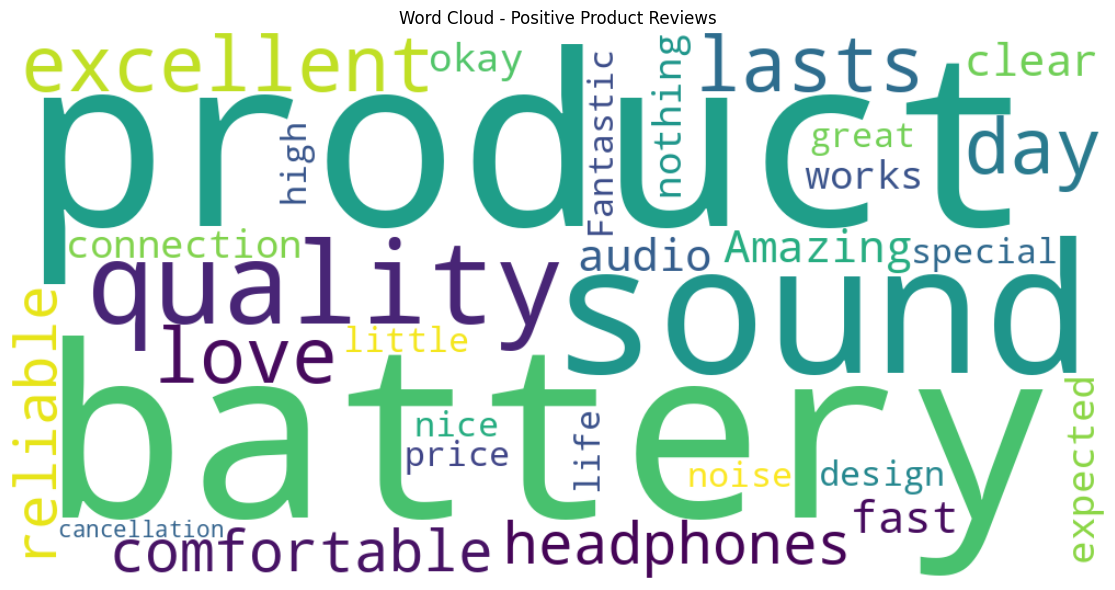


Word cloud saved as positive_reviews_wordcloud.png


In [36]:
positive_text = " ".join(positive_reviews)
if positive_text.strip():
    cloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        stopwords=STOP_WORDS,
        collocations=False
    ).generate(positive_text)

    cloud.to_file("positive_reviews_wordcloud.png")
    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud - Positive Product Reviews")
    plt.tight_layout()
    plt.savefig("positive_reviews_wordcloud_display.png", dpi=150)
    plt.show()
    print("\nWord cloud saved as positive_reviews_wordcloud.png")
else:
    print("\nNo positive reviews found; word cloud was not generated.")

sentiment_df.to_csv("sentiment_analysis.csv", index=False)

In [37]:
print("Q6: TEXT GENERATION USING KERAS LSTM")


Q6: TEXT GENERATION USING KERAS LSTM


In [39]:
training_text = """
Technology helps people solve problems and share knowledge.
Students learn programming by writing code and building useful applications.
Artificial intelligence allows computers to discover patterns in information.
Machine learning uses examples to improve predictions over time.
Good software is designed carefully, tested regularly, and improved continuously.
Computer networks connect devices and allow people to communicate around the world.
Cybersecurity protects information from attacks and unauthorized access.
Data science helps researchers understand information and make better decisions.
Learning new skills requires curiosity, patience, practice, and creativity.
The future of technology depends on responsible people who build helpful systems.
"""


In [40]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1
input_sequences = []

for line in training_text.strip().split("\n"):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

if not input_sequences:
    raise ValueError("Not enough training text to create input sequences.")

max_sequence_len = max(len(sequence) for sequence in input_sequences)
padded_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]
y = np.asarray(y)

print("\n1. Vocabulary size:", total_words)
print("Number of input sequences:", len(input_sequences))
print("Padded sequence shape:", padded_sequences.shape)


1. Vocabulary size: 82
Number of input sequences: 87
Padded sequence shape: (87, 12)


In [41]:
model = Sequential([
    Embedding(total_words, 64, input_length=max_sequence_len - 1),
    LSTM(100),
    Dropout(0.2),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

print("\n2. LSTM model summary:")
model.summary()



2. LSTM model summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [42]:
print("\nTraining model. Please wait...")
model.fit(X, y, epochs=150, verbose=0)
print("Model training completed.")

def generate_text(seed_text, next_words=12):
    generated = seed_text.lower()

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([generated])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )

        probabilities = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(probabilities))

        if predicted_id == 0:
            break

        output_word = tokenizer.index_word.get(predicted_id)
        if output_word is None:
            break

        generated += " " + output_word

    return generated

seed_word = "technology"
print(f"\n3. Generated text using seed word '{seed_word}':")
for line_number in range(1, 4):
    generated_line = generate_text(seed_word, next_words=12)
    print(f"Generated line {line_number}: {generated_line}")


Training model. Please wait...
Model training completed.

3. Generated text using seed word 'technology':
Generated line 1: technology helps people solve problems and share knowledge knowledge around the world world
Generated line 2: technology helps people solve problems and share knowledge knowledge around the world world
Generated line 3: technology helps people solve problems and share knowledge knowledge around the world world


In [44]:
model.save("nlp_text_generator.keras")

bow_df.to_csv("bag_of_words.csv")
tfidf_df.to_csv("tfidf_scores.csv")

# Save comparison if it exists
if "comparison_df" in globals():
    comparison_df.to_csv(
        "stemming_lemmatization_comparison.csv",
        index=False
    )
elif "comparison" in globals():
    comparison.to_csv(
        "stemming_lemmatization_comparison.csv",
        index=False
    )
else:
    print("Run Q2 first to generate comparison data.")

frequency_df.to_csv("word_frequency.csv")

print("ALL QUESTIONS Q1-Q6 COMPLETED")

ALL QUESTIONS Q1-Q6 COMPLETED
